# RSNA Knee Abnormality Detection — Data Analysis

Comprehensive EDA of the competition metadata (`train.csv`, `train_series.csv`, `test*.csv`).
Pixel-level analysis comes later, once a DICOM sample is available.

**Task**: 12 binary findings per *study*, scored by macro-averaged AUROC.

In [1]:
# --- 01: setup & load -------------------------------------------------------
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.dpi"] = 110

RAW = Path("../data/raw")

# The 12 targets, in the exact column order the submission file expects.
LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
          "Medial OA", "Lateral OA", "PF OA", "Effusion",
          "Synovitis", "Baker's", "Contusion", "Fracture"]

train      = pd.read_csv(RAW / "train.csv")
train_ser  = pd.read_csv(RAW / "train_series.csv")
test       = pd.read_csv(RAW / "test.csv")
test_ser   = pd.read_csv(RAW / "test_series.csv")
sample_sub = pd.read_csv(RAW / "sample_submission.csv")

for name, df in [("train", train), ("train_series", train_ser),
                 ("test", test), ("test_series", test_ser),
                 ("sample_submission", sample_sub)]:
    print(f"{name:20s} {str(df.shape):>12s}   {list(df.columns)}")

print()
print("submission column order matches LABELS:",
      list(sample_sub.columns) == ["StudyInstanceUID"] + LABELS)
print("train label columns match LABELS:      ",
      [c for c in train.columns if c in LABELS] == LABELS)

display(train.head(3))

train                  (4407, 14)   ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']
train_series           (24371, 5)   ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']
test                       (3, 1)   ['StudyInstanceUID']
test_series               (15, 5)   ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']
sample_submission         (3, 13)   ['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

submission column order matches LABELS: True
train label columns match LABELS:       True


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260,Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura d...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585,"[DATE]: * MR Knie Rechts 15ch AA Klinische Inlichtingen: [DATE]. Diagnostische vraagstellling: Meniscusscheur/mediaal? Scanprotocol (DRB) : sag intermediair gewogen seq zonder en met fs, ax/ cor p...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231,Hallazgos:\nNo hay alteraciones en significativas de la médula ósea.\nLigamentos cruzados y colaterales dentro de límites normales.\nAumento de señal del cuerno posterior del menisco medial que no...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=== how many studies actually carry labels ===
studies in train.csv        : 4407
fully labeled (all 12)      : 58
partially labeled (1..11)   : 0
unlabeled (0 of 12)         : 4349
-> labeled fraction         : 1.32%

label values seen (should be only 0/1): [np.float64(0.0), np.float64(1.0)]

=== per-finding prevalence among the labeled studies ===


,positives,negatives,prevalence_%
Effusion,35,23,60.3
Synovitis,27,31,46.6
Medial Meniscus,26,32,44.8
ACL,24,34,41.4
Lateral Meniscus,23,35,39.7
PF OA,21,37,36.2
Contusion,19,39,32.8
Fracture,18,40,31.0
Medial OA,15,43,25.9
Baker's,12,46,20.7


=== number of positive findings per labeled study ===
1     8
2     7
3    11
4     7
5     9
6     7
7     5
8     1
9     3
mean findings per knee: 4.14   studies with zero findings: 0


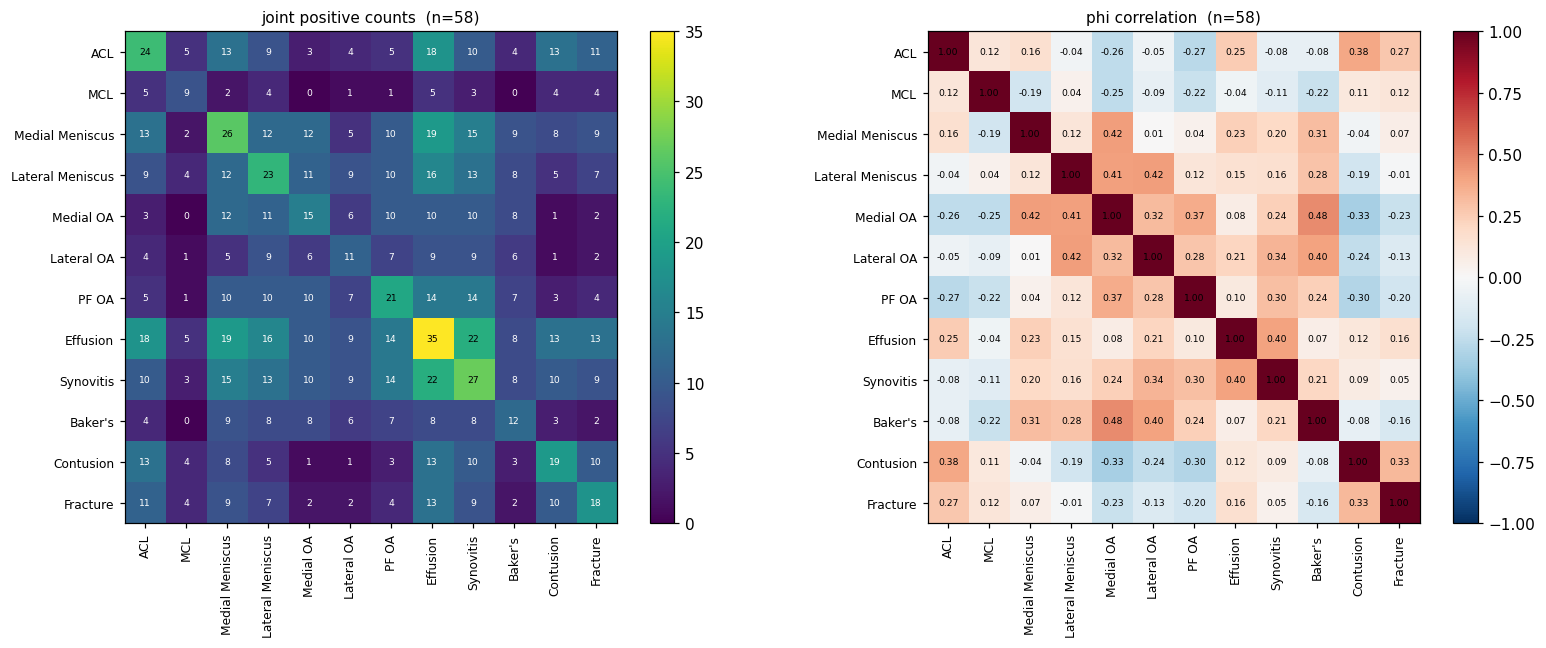

=== most positively correlated pairs ===
Medial OA         Baker's       0.48
Medial Meniscus   Medial OA     0.42
Lateral Meniscus  Lateral OA    0.42
                  Medial OA     0.41
Lateral OA        Baker's       0.40
Effusion          Synovitis     0.40

=== most negatively correlated pairs ===
Lateral OA  Contusion   -0.24
MCL         Medial OA   -0.25
ACL         Medial OA   -0.26
            PF OA       -0.27
PF OA       Contusion   -0.30
Medial OA   Contusion   -0.33


In [2]:
# --- 02: label coverage, prevalence, co-occurrence ---------------------------
# A label is NaN ("Not a Number" = missing) when nobody hand-annotated that study.
lab = train[LABELS]
n_present = lab.notna().sum(axis=1)          # how many of the 12 are filled in per study

print("=== how many studies actually carry labels ===")
print(f"studies in train.csv        : {len(train)}")
print(f"fully labeled (all 12)      : {(n_present == 12).sum()}")
print(f"partially labeled (1..11)   : {n_present.between(1, 11).sum()}")
print(f"unlabeled (0 of 12)         : {(n_present == 0).sum()}")
print(f"-> labeled fraction         : {(n_present == 12).mean():.2%}")

labeled   = train[n_present == 12].reset_index(drop=True)
unlabeled = train[n_present == 0].reset_index(drop=True)
print(f"\nlabel values seen (should be only 0/1): {sorted(pd.unique(labeled[LABELS].values.ravel()))}")

# --- prevalence: how often is each finding positive, among the labeled studies?
y = labeled[LABELS].astype(int)
prev = pd.DataFrame({
    "positives": y.sum(),
    "negatives": (1 - y).sum(),
    "prevalence_%": (y.mean() * 100).round(1),
}).sort_values("prevalence_%", ascending=False)
print("\n=== per-finding prevalence among the labeled studies ===")
display(prev)

# --- how many findings does one knee have at once?
print("=== number of positive findings per labeled study ===")
counts = y.sum(axis=1).value_counts().sort_index()
print(counts.to_string())
print(f"mean findings per knee: {y.sum(axis=1).mean():.2f}   "
      f"studies with zero findings: {(y.sum(axis=1) == 0).sum()}")

# --- co-occurrence. Two views:
#   (a) raw counts of studies where both findings are positive
#   (b) phi correlation: +1 = always together, -1 = never together, 0 = unrelated
#       (phi is just Pearson correlation applied to 0/1 variables)
co    = y.T.dot(y)
phi   = y.corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, mat, title, kw in [
    (axes[0], co,  "joint positive counts", dict(cmap="viridis")),
    (axes[1], phi, "phi correlation",       dict(cmap="RdBu_r", vmin=-1, vmax=1)),
]:
    im = ax.imshow(mat.values, **kw)
    ax.set_xticks(range(12)); ax.set_xticklabels(LABELS, rotation=90, fontsize=8)
    ax.set_yticks(range(12)); ax.set_yticklabels(LABELS, fontsize=8)
    ax.set_title(f"{title}  (n={len(y)})", fontsize=10)
    for i in range(12):
        for j in range(12):
            v = mat.values[i, j]
            ax.text(j, i, f"{v:.0f}" if mat is co else f"{v:.2f}",
                    ha="center", va="center", fontsize=6,
                    color="w" if (mat is co and v < co.values.max() * .6) else "k")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# strongest pairs, ignoring the diagonal (.dropna() removes the masked lower triangle)
pairs = (phi.where(np.triu(np.ones(phi.shape), 1).astype(bool))
            .stack().dropna().sort_values(ascending=False))
print("=== most positively correlated pairs ===")
print(pairs.head(6).round(2).to_string())
print("\n=== most negatively correlated pairs ===")
print(pairs.tail(6).round(2).to_string())


=== report size ===


,chars,words,lines
count,4407.0,4407.0,4407.0
mean,1097.9,147.5,13.3
std,693.9,95.3,15.9
min,52.0,8.0,1.0
5%,205.0,28.0,1.0
25%,587.5,74.5,1.0
50%,977.0,129.0,2.0
75%,1459.5,202.0,22.0
95%,2452.7,330.0,50.0
99%,3101.9,414.0,55.0


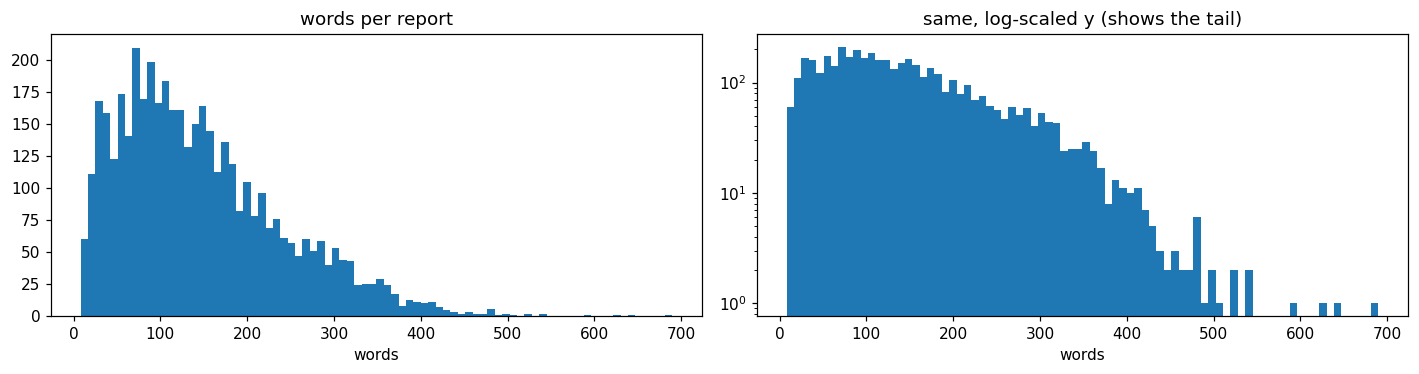

shortest report:
 'Técnica: RMN de la rodilla. Resultados: . Impresión:'

=== duplicates ===
exactly duplicated report texts: 177 rows, 46 distinct texts
  x37: 'Diz eklemi içi sıvı miktarı normal. Çapraz ve yan bağlar normal. Medyal ve lateral menisküs normal. Eklem kıkırdakları ve kemikler normal. Ekstensör m'
  x14: 'Técnica: RMN de la rodilla. Resultados: Pinzamiento de la almohadilla grasa de Hoffa. Impresión: Pinzamiento de la almohadilla grasa de Hoffa'
  x12: 'Técnica: RMN de la rodilla. Resultados: Sin anomalías. Impresión: Sin anomalías'


In [ ]:
# --- 03: the radiology reports — length, language, structure -----------------
# Every one of the 4407 studies has a report, so this text is the only route to
# labels for the 4349 unlabeled studies. First: what are we actually dealing with?
#
# Needs one small package for language identification:  pip install langdetect
import re
from collections import Counter

rep = train["Report"].fillna("")

print("=== report size ===")
size = pd.DataFrame({
    "chars": rep.str.len(),
    "words": rep.str.split().str.len(),
    "lines": rep.str.count(r"\n") + 1,
})
display(size.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(size["words"], bins=80); axes[0].set_title("words per report"); axes[0].set_xlabel("words")
axes[1].hist(size["words"], bins=80); axes[1].set_yscale("log")
axes[1].set_title("same, log-scaled y (shows the tail)"); axes[1].set_xlabel("words")
plt.tight_layout(); plt.show()

print("shortest report:\n", repr(rep[size["chars"].idxmin()]))

# --- exact duplicates: templated or copy-pasted reports?
dupe = rep.duplicated(keep=False)
print(f"\n=== duplicates ===\nexactly duplicated report texts: {dupe.sum()} rows, "
      f"{rep[dupe].nunique()} distinct texts")
if dupe.any():
    for text, n in rep[dupe].value_counts().head(3).items():
        print(f"  x{n}: {text[:150]!r}")

# --- language identification
try:
    from langdetect import detect, DetectorFactory
    DetectorFactory.seed = 0                      # deterministic output
    def _lang(t):
        try:
            return detect(t[:2000])
        except Exception:
            return "??"
    train["lang"] = [_lang(t) for t in rep]
except ImportError:
    print("\n[!] langdetect not installed -> run: pip install langdetect")
    train["lang"] = "??"

print("\n=== detected language of each report ===")
lang_counts = train["lang"].value_counts()
display(pd.DataFrame({"reports": lang_counts,
                      "%": (lang_counts / len(train) * 100).round(1)}))

# do the 58 labeled studies cover the same languages as the rest?
print("=== language of the 58 labeled studies ===")
print(train.loc[n_present == 12, "lang"].value_counts().to_string())

# --- structure: do reports use section headings we can exploit?
HEADINGS = ["findings", "impression", "conclusion", "technique", "comparison",
            "history", "hallazgos", "impresi", "tecnica", "técnica", "conclusi",
            "bevindingen", "besluit", "befund", "beurteilung"]
print("\n=== how many reports contain each section heading (case-insensitive) ===")
low = rep.str.lower()
for h in HEADINGS:
    n = low.str.contains(h, regex=False).sum()
    if n:
        print(f"  {h:14s} {n:5d}  ({n / len(rep):.1%})")

# --- placeholder tokens left behind by the de-identification process
print("\n=== bracketed placeholders (de-identification artifacts) ===")
print(dict(Counter(re.findall(r"\[[A-Za-z_ ]{2,20}\]", " ".join(rep))).most_common(10)))


# --- eyeball one full report from each of the 4 most common languages
print("\n" + "=" * 90)
for lg in lang_counts.head(4).index:
    ex = train.loc[train["lang"] == lg, "Report"].iloc[0]
    print(f"--- lang={lg} ---\n{ex[:900]}\n" + "=" * 90)


=== how much real content is left after stripping boilerplate ===
  <=  0 content words :   36  (0.82%)
  <=  3 content words :  151  (3.43%)
  <=  5 content words :  260  (5.90%)
  <= 10 content words :  464  (10.53%)
  <= 20 content words :  640  (14.52%)

examples of the emptiest reports:
  [ 0 words] 'МР находка: Няма МР данни за ставен излив. Костите, формиращи дясната колянна  става са с нормална форма и стр'
  [ 0 words] 'МР находка: МР данни за малък ставен излив. Вижда се изразен костномозъчен едем в латералния кондил на тибията'
  [ 0 words] 'МР находка: МР данни за ставен излив. Костите, формиращи дясната колянна става се изобразяват с правилна форма'
  [ 0 words] 'МР находка: Костите, формиращи лявата колянна става са с нормална форма и интензитет на сигнала. Няма данни за'
  [ 0 words] 'МР находка: Костите, формиращи лявата колянна  става са с нормална форма и сигнален интензитет. Няма данни за '

=== negation cues ===
reports containing >=1 negation cue : 4082 (92.6%)
med

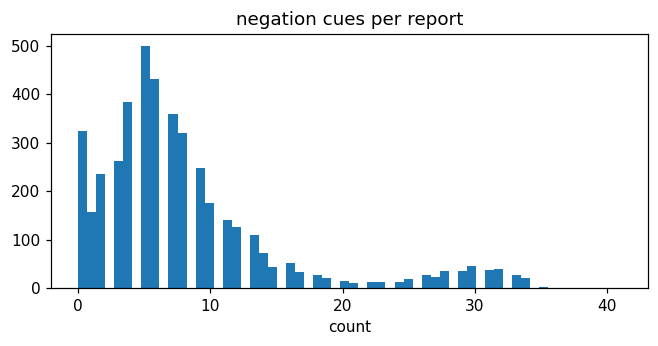

=== mean negation cues by language ===
      mean_neg  mean_words
lang                      
en        12.5       187.0
fr         9.7       242.0
de         8.2        92.0
bg         7.2       160.0
hr         5.6       146.0
nl         5.5       118.0
es         5.2       113.0
tr         5.0        90.0
el         2.7       133.0

reports with >=3 negation cues and real content: 3393 (77.0%) — candidate all-negative studies


In [4]:
# --- 04a: unusable reports, and how much of the text is negation -------------
# Two questions before we try to derive labels from text:
#   1. how many reports say nothing at all (empty templates)?
#   2. how dominant is negated language ("no tear", "intact", "normal")?
#      Negation is the main trap: a keyword matcher reads "the ACL is not torn"
#      as an ACL tear. Below we measure how often that trap is set.

# Words that flip the meaning of a sentence, per language.
NEGATION = {
    "en": ["no ", "not ", "without", "intact", "normal", "unremarkable", "absence", "negative for"],
    "es": ["no ", "sin ", "normal", "íntegr", "integr", "ausencia", "conservad"],
    "tr": ["yok", "yoktur", "normal", "doğal", "izlenmedi", "saptanmadı", "görülmedi", "sağlam"],
    "hr": ["bez", "uredn", "nema", "očuvan", "intakt"],
    "el": ["χωρίς", "δεν ", "φυσιολογ", "ακέραι", "απουσία"],
    "de": ["kein", "ohne", "unauffällig", "intakt", "normal", "regelrecht"],
    "bg": ["без", "не ", "нормал", "интакт", "запазен"],
    "nl": ["geen", "zonder", "intact", "normaal", "niet "],
    "fr": ["pas de", "sans", "absence", "normal", "intact", "aucun"],
}
ALL_NEG = sorted({w for ws in NEGATION.values() for w in ws})

low = train["Report"].fillna("").str.lower()

# --- 1. reports with (almost) no content
#     Strip the boilerplate scaffolding and see what's actually left.
SCAFFOLD = r"(t[eé]cnica|resultados|impresi[oó]n|findings|impression|conclusion|" \
           r"technique|bulgular|sonu[cç]|bevindingen|besluit)\s*:?"
stripped = (low.str.replace(SCAFFOLD, " ", regex=True)
               .str.replace(r"\[[a-z_ ]{2,20}\]", " ", regex=True)   # [DATE], [NAME], ...
               .str.replace(r"[^\w\s]", " ", regex=True)
               .str.split().str.join(" "))
content_words = stripped.str.split().str.len()

print("=== how much real content is left after stripping boilerplate ===")
for thr in [0, 3, 5, 10, 20]:
    n = (content_words <= thr).sum()
    print(f"  <= {thr:2d} content words : {n:4d}  ({n / len(train):.2%})")

print("\nexamples of the emptiest reports:")
for i in content_words.nsmallest(5).index:
    print(f"  [{content_words[i]:2d} words] {train.loc[i, 'Report'][:110]!r}")

# --- 2. negation density
neg_hits = pd.Series([sum(t.count(w) for w in ALL_NEG) for t in low], index=low.index)
print("\n=== negation cues ===")
print(f"reports containing >=1 negation cue : {(neg_hits > 0).sum()} ({(neg_hits > 0).mean():.1%})")
print(f"median negation cues per report     : {neg_hits.median():.0f}")
print(f"mean negation cues per report       : {neg_hits.mean():.1f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(neg_hits, bins=60)
ax.set_title("negation cues per report"); ax.set_xlabel("count"); plt.show()

# A knee can be described as normal in one language and abnormal in another,
# so check negation density is not just an artifact of one site's template.
print("=== mean negation cues by language ===")
print(pd.DataFrame({"mean_neg": neg_hits.groupby(train["lang"]).mean().round(1),
                    "mean_words": train["Report"].str.split().str.len()
                                  .groupby(train["lang"]).mean().round(0)})
      .sort_values("mean_neg", ascending=False).to_string())

# --- 3. how often does an "all normal" report appear?
#     These are gold: the 58 labeled studies contain zero normal knees, so
#     confidently-negative studies have to come from the text.
normal_ish = (neg_hits >= 3) & (content_words > 10)
print(f"\nreports with >=3 negation cues and real content: {normal_ish.sum()} "
      f"({normal_ish.mean():.1%}) — candidate all-negative studies")


In [5]:
# --- 04b: naive multilingual keyword matcher = the baseline to beat ----------
# Rule per finding: a sentence must mention the ANATOMY *and* a PATHOLOGY word,
# and must not contain a negation cue. For findings that are themselves the
# pathology (Effusion, Synovitis, Baker's, Fracture) the pathology word alone is
# enough. Scored against the 58 hand-labeled studies — whatever this reaches,
# the language model has to beat it, or the language model is not worth running.
KW = {
    # (anatomy terms, pathology terms). Empty anatomy = pathology word suffices.
    "ACL": (["anterior cruciate", "acl", "ligamento cruzado anterior", "lca",
             "ön çapraz", "on capraz", "öçb", "prednji križni", "prednji krizni",
             "πρόσθιο χιαστό", "πρόσθιος χιαστός", "vordere kreuzband", "vorderen kreuzband",
             "предна кръстна", "voorste kruisband", "ligament croisé antérieur"], "TEAR"),
    "MCL": (["medial collateral", "mcl", "colateral medial", "colateral interno",
             "iç yan bağ", "ic yan bag", "medial kollateral", "medijalni kolateralni",
             "έσω πλάγιο", "έσω πλάγιος", "innenband", "mediales kollateral",
             "медиален колатерален", "mediale collaterale", "collatéral médial",
             "collatéral interne"], "TEAR"),
    "Medial Meniscus": (["medial meniscus", "menisco interno", "menisco medial",
                         "medial menisküs", "iç menisküs", "ic menisküs", "medijalni menisk",
                         "έσω μηνίσκο", "innenmeniskus", "medialer meniskus", "medialen meniskus",
                         "медиален менискус", "вътрешен менискус", "mediale meniscus",
                         "ménisque interne", "ménisque médial"], "TEAR"),
    "Lateral Meniscus": (["lateral meniscus", "menisco externo", "menisco lateral",
                          "lateral menisküs", "dış menisküs", "dis menisküs", "lateralni menisk",
                          "έξω μηνίσκο", "außenmeniskus", "aussenmeniskus", "lateraler meniskus",
                          "латерален менискус", "външен менискус", "laterale meniscus",
                          "ménisque externe", "ménisque latéral"], "TEAR"),
    "Medial OA": (["medial", "interno", "iç ", "medijaln", "έσω", "медиал", "вътреш",
                   "mediaal", "mediale", "innen"], "OA"),
    "Lateral OA": (["lateral", "externo", "dış ", "dis ", "lateraln", "έξω", "латерал",
                    "външ", "außen", "aussen"], "OA"),
    "PF OA": (["patellofemoral", "patelofemoral", "femoropatel", "retropatel",
               "patellofemoraal", "επιγονατιδομηριαί", "пателофеморал", "patella"], "OA"),
    "Effusion": ([], ["effusion", "joint fluid", "derrame", "efüzyon", "eklem içi sıvı",
                      "mayi", "sıvı artış", "izljev", "izliv", "αρθρικό υγρό", "συλλογή υγρού",
                      "erguss", "излив", "изливи", "gewrichtsvocht", "vochtcollectie",
                      "épanchement"]),
    "Synovitis": ([], ["synovitis", "sinovitis", "sinovit", "synovitida", "sinovijalna upala",
                       "υμενίτιδα", "synovialitis", "синовит", "synovite", "synoviale hypertrof",
                       "sinovyal"]),
    "Baker's": ([], ["baker", "popliteal cyst", "quiste poplíteo", "poplit kist",
                     "poplitealna cista", "κύστη baker", "poplitealzyste", "bakerzyste",
                     "поплитеална киста", "bakerse cyste", "kyste poplité"]),
    "Contusion": ([], ["contusion", "bone bruise", "bone marrow edema", "bone marrow oedema",
                       "contusión", "edema óseo", "edema de médula ósea", "kontüzyon",
                       "kemik iliği ödem", "kontuzija", "koštani edem", "μυελικό οίδημα",
                       "knochenmarködem", "knochenmarkoedem", "костен оток", "костномозъчен оток",
                       "botcontusie", "beenmergoedeem", "contusion osseuse", "œdème osseux"]),
    "Fracture": ([], ["fracture", "fractura", "kırık", "kirik", "fraktür", "fraktura",
                      "prijelom", "κάταγμα", "fraktur", "фрактура", "счупване", "fractuur"]),
}
# pathology vocabularies shared by several findings
TEAR = ["tear", "torn", "rupture", "ruptur", "rotura", "desgarro", "yırtık", "yirtik",
        "rüptür", "ruptura", "puknuće", "ρήξη", "riss", "разкъсване", "руптура",
        "scheur", "ruptuur", "déchirure", "lesion", "lesión", "lezija", "signal alteration"]
OA = ["osteoarthritis", "osteoarthrosis", "arthrosis", "chondrosis", "chondral loss",
      "cartilage loss", "chondromalacia", "degenerative", "artrosis", "gonartrosis",
      "condropatía", "condromalacia", "gonartroz", "osteoartrit", "kondropati",
      "kondromalazi", "artroza", "gonartroza", "hondropatija", "οστεοαρθρίτιδα",
      "γοναρθρίτιδα", "χονδροπάθεια", "arthrose", "gonarthrose", "chondropathie",
      "knorpelschaden", "остеоартрит", "гонартроза", "хондропатия", "artrose",
      "kraakbeenverlies", "chondropathie"]
VOCAB = {"TEAR": TEAR, "OA": OA}

SENT_SPLIT = re.compile(r"[.\n;•]+")

def keyword_labels(text: str) -> dict:
    """Apply the rules above to one report, returning 12 zeros/ones."""
    out = {k: 0 for k in LABELS}
    for sent in SENT_SPLIT.split(text.lower()):
        if not sent.strip():
            continue
        if any(n in sent for n in ALL_NEG):        # negated sentence -> ignore entirely
            continue
        for label, (anat, path) in KW.items():
            words = VOCAB[path] if isinstance(path, str) else path
            if any(p in sent for p in words) and (not anat or any(a in sent for a in anat)):
                out[label] = 1
    return out

pred_all = pd.DataFrame([keyword_labels(t) for t in train["Report"].fillna("")],
                        index=train.index)[LABELS]

print("=== keyword matcher: predicted prevalence over ALL 4407 reports ===")
print((pred_all.mean() * 100).round(1).sort_values(ascending=False).to_string())
print(f"\nstudies predicted completely negative: {(pred_all.sum(axis=1) == 0).sum()} "
      f"({(pred_all.sum(axis=1) == 0).mean():.1%})")
print(f"mean findings per study: {pred_all.sum(axis=1).mean():.2f}")

# --- score against the 58 hand-labeled studies
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

mask = (n_present == 12)
yt, yp = train.loc[mask, LABELS].astype(int), pred_all.loc[mask]
rows = []
for c in LABELS:
    t, p = yt[c].values, yp[c].values
    rows.append({
        "label": c, "true_pos": t.sum(), "pred_pos": p.sum(),
        "precision": precision_score(t, p, zero_division=0),
        "recall": recall_score(t, p, zero_division=0),
        "f1": f1_score(t, p, zero_division=0),
        # AUROC on a 0/1 prediction == balanced accuracy; a weak but comparable number
        "auroc": roc_auc_score(t, p) if len(set(t)) > 1 else np.nan,
    })
res = pd.DataFrame(rows).set_index("label").round(3)
print("\n=== keyword matcher vs the 58 ground-truth studies ===")
display(res)
print(f"MACRO AUROC (the competition metric) = {res['auroc'].mean():.4f}")
print("This is the floor. A language model reading the reports should reach ~0.95+.")


=== keyword matcher: predicted prevalence over ALL 4407 reports ===
Effusion            56.2
Medial Meniscus     25.7
Baker's             22.3
Contusion           18.0
Medial OA           16.8
PF OA               16.1
Lateral OA          11.4
ACL                 10.9
Lateral Meniscus    10.4
Synovitis           10.3
Fracture             6.1
MCL                  2.7

studies predicted completely negative: 875 (19.9%)
mean findings per study: 2.07

=== keyword matcher vs the 58 ground-truth studies ===


,true_pos,pred_pos,precision,recall,f1,auroc
label,,,,,,
ACL,24,20,0.900,0.750,0.818,0.846
MCL,9,6,0.667,0.444,0.533,0.702
Medial Meniscus,26,20,0.850,0.654,0.739,0.780
Lateral Meniscus,23,14,0.786,0.478,0.595,0.696
Medial OA,15,13,0.538,0.467,0.500,0.664
Lateral OA,11,10,0.600,0.545,0.571,0.730
PF OA,21,7,0.286,0.095,0.143,0.480
Effusion,35,46,0.674,0.886,0.765,0.617
Synovitis,27,14,0.714,0.370,0.488,0.621


MACRO AUROC (the competition metric) = 0.7003
This is the floor. A language model reading the reports should reach ~0.95+.


In [6]:
# --- 05: series composition — what imaging does each study actually contain? -
# At test time the model sees ONLY images. train_series.csv describes each
# acquisition with three flags:
#   Anatomical_Plane : Sagittal / Coronal / Axial  (which direction the slices cut)
#   Fluid_Sensitive  : 1 if fluid appears bright (T2/PD/STIR) -> swelling, tears
#   Fat_Suppression  : 1 if fat was darkened     -> lets bright fluid stand out
# If the protocol is consistent across sites we can rely on picking, say, "the
# sagittal fluid-sensitive series". If it isn't, the model must handle whatever
# it is given.
ts = train_ser.copy()

print("=== series per study ===")
spc = ts.groupby("StudyInstanceUID").size()
print(spc.describe().round(2).to_string())
print("\ndistribution:")
print(spc.value_counts().sort_index().to_string())

print("\n=== the three flags on their own ===")
for col in ["Anatomical_Plane", "Fluid_Sensitive", "Fat_Suppression"]:
    vc = ts[col].value_counts(dropna=False)
    print(f"\n{col}:")
    print(pd.DataFrame({"series": vc, "%": (vc / len(ts) * 100).round(1)}).to_string())

# Are Fluid_Sensitive and Fat_Suppression the same column in disguise?
# (cell-01 output hinted at it: both split 14010 / 10361)
print("\n=== are Fluid_Sensitive and Fat_Suppression independent? ===")
ct = pd.crosstab(ts["Fluid_Sensitive"], ts["Fat_Suppression"])
display(ct)
print("identical on every row:", ts["Fluid_Sensitive"].equals(ts["Fat_Suppression"]))

# --- the full protocol signature: plane x fluid x fat
ts["combo"] = (ts["Anatomical_Plane"].astype(str) + " | fluid=" +
               ts["Fluid_Sensitive"].astype(str) + " | fat=" +
               ts["Fat_Suppression"].astype(str))
combo = ts["combo"].value_counts()
print("\n=== every plane x fluid x fat combination seen ===")
display(pd.DataFrame({"series": combo, "%": (combo / len(ts) * 100).round(1)}))

# --- per study: which combos does a study have, and how universal are they?
have = ts.pivot_table(index="StudyInstanceUID", columns="combo",
                      values="SeriesInstanceUID", aggfunc="count").fillna(0)
cov = (have > 0).mean().sort_values(ascending=False)
print("=== fraction of the 4407 studies that contain each combo ===")
print((cov * 100).round(1).to_string())

# --- how many studies cover all three planes?
planes = ts.pivot_table(index="StudyInstanceUID", columns="Anatomical_Plane",
                        values="SeriesInstanceUID", aggfunc="count").fillna(0) > 0
print("\n=== plane coverage per study ===")
print(f"has all 3 planes : {planes.all(axis=1).sum():5d}  ({planes.all(axis=1).mean():.1%})")
for p in ["Sagittal", "Coronal", "Axial"]:
    if p in planes:
        print(f"has {p:9s}: {planes[p].sum():5d}  ({planes[p].mean():.1%})")
print("\nexact plane-set combinations across studies:")
print(planes.apply(lambda r: "+".join(sorted(planes.columns[r])), axis=1)
            .value_counts().to_string())

# --- a study with NO fluid-sensitive series would be hard to read
fs = ts.groupby("StudyInstanceUID")["Fluid_Sensitive"].max()
print(f"\nstudies with zero fluid-sensitive series: {(fs == 0).sum()} ({(fs == 0).mean():.1%})")

# --- does the protocol differ by reporting language (i.e. by site)?
lang_map = train.set_index("StudyInstanceUID")["lang"]
ts["lang"] = ts["StudyInstanceUID"].map(lang_map)
print("\n=== mean series per study, and plane mix, by language(=site) ===")
by_lang = pd.DataFrame({
    "studies": ts.groupby("lang")["StudyInstanceUID"].nunique(),
    "series/study": (ts.groupby("lang").size() /
                     ts.groupby("lang")["StudyInstanceUID"].nunique()).round(2),
    "% fluid_sens": (ts.groupby("lang")["Fluid_Sensitive"].mean() * 100).round(1),
})
plane_mix = (pd.crosstab(ts["lang"], ts["Anatomical_Plane"], normalize="index") * 100).round(1)
display(by_lang.join(plane_mix))


=== series per study ===
count    4407.00
mean        5.53
std         1.39
min         3.00
25%         5.00
50%         5.00
75%         6.00
max        14.00

distribution:
3        1
4      675
5     2299
6      698
7      310
8      145
9      176
10      74
11      21
12       5
13       2
14       1

=== the three flags on their own ===

Anatomical_Plane:
                  series     %
Anatomical_Plane              
Sagittal            9864  40.5
Coronal             8609  35.3
Axial               5898  24.2

Fluid_Sensitive:
                 series     %
Fluid_Sensitive              
1                 14010  57.5
0                 10361  42.5

Fat_Suppression:
                 series     %
Fat_Suppression              
1                 14010  57.5
0                 10361  42.5

=== are Fluid_Sensitive and Fat_Suppression independent? ===


Fat_Suppression,0,1
Fluid_Sensitive,,
0,10361,0
1,0,14010


identical on every row: True

=== every plane x fluid x fat combination seen ===


,series,%
combo,,
Sagittal | fluid=0 | fat=0,5197,21.3
Axial | fluid=1 | fat=1,4719,19.4
Sagittal | fluid=1 | fat=1,4667,19.1
Coronal | fluid=1 | fat=1,4624,19.0
Coronal | fluid=0 | fat=0,3985,16.4
Axial | fluid=0 | fat=0,1179,4.8


=== fraction of the 4407 studies that contain each combo ===
combo
Axial | fluid=1 | fat=1       100.0
Sagittal | fluid=0 | fat=0     96.8
Coronal | fluid=1 | fat=1      96.4
Sagittal | fluid=1 | fat=1     94.2
Coronal | fluid=0 | fat=0      77.3
Axial | fluid=0 | fat=0        19.4

=== plane coverage per study ===
has all 3 planes :  4407  (100.0%)
has Sagittal :  4407  (100.0%)
has Coronal  :  4407  (100.0%)
has Axial    :  4407  (100.0%)

exact plane-set combinations across studies:
Axial+Coronal+Sagittal    4407

studies with zero fluid-sensitive series: 0 (0.0%)

=== mean series per study, and plane mix, by language(=site) ===


,studies,series/study,% fluid_sens,Axial,Coronal,Sagittal
lang,,,,,,
bg,220,5.64,56.6,19.7,37.1,43.2
de,262,5.26,41.2,39.4,21.1,39.4
el,321,4.83,63.0,22.0,42.3,35.6
en,1736,5.80,57.4,27.3,31.6,41.0
es,682,5.26,60.1,22.3,38.4,39.3
fr,81,4.09,75.5,25.4,25.1,49.5
hr,406,5.81,52.5,17.6,47.3,35.1
nl,153,5.04,59.9,20.4,39.6,40.1
tr,546,5.63,60.9,18.1,36.8,45.0


In [8]:
# --- 06: can every study fill the 4 model input slots? -----------------------
# The plan is to feed the model 4 fixed slots. Cell 05 showed each slot alone is
# present in 94-100% of studies, but what matters is how many studies have ALL
# four at once, and what the stragglers have instead.
SLOTS = {
    "sag_plain": ("Sagittal", 0),
    "sag_fluid": ("Sagittal", 1),
    "cor_fluid": ("Coronal",  1),
    "ax_fluid":  ("Axial",    1),
}

# one boolean column per slot, indexed by study
present = pd.DataFrame(index=sorted(train_ser["StudyInstanceUID"].unique()))
for name, (plane, fluid) in SLOTS.items():
    hits = train_ser[(train_ser["Anatomical_Plane"] == plane) &
                     (train_ser["Fluid_Sensitive"] == fluid)]["StudyInstanceUID"].unique()
    present[name] = present.index.isin(hits)

n_slots = present.sum(axis=1)
print("=== how many of the 4 slots each study can fill ===")
for k in range(5):
    n = (n_slots == k).sum()
    print(f"  {k} of 4 slots : {n:5d}  ({n / len(present):6.2%})")
print(f"\nSTUDIES WITH ALL 4 SLOTS: {(n_slots == 4).sum()} of {len(present)} "
      f"({(n_slots == 4).mean():.2%})")

print("\n=== exactly which slot-sets occur ===")
combo6 = present.apply(lambda r: "+".join(present.columns[r]) or "(none)", axis=1)
print(combo6.value_counts().to_string())

# --- what do the incomplete studies actually contain instead?
incomplete = present.index[n_slots < 4]
print(f"\n=== the {len(incomplete)} incomplete studies: what series do they have? ===")
sub = train_ser[train_ser["StudyInstanceUID"].isin(incomplete)]
print((sub["Anatomical_Plane"] + " | fluid=" + sub["Fluid_Sensitive"].astype(str))
      .value_counts().to_string())
print("\nseries count for incomplete studies:")
print(sub.groupby("StudyInstanceUID").size().value_counts().sort_index().to_string())

# --- proposed fallback: substitute another series in the SAME plane
print("\n=== fallback check: does a same-plane substitute always exist? ===")
for name, (plane, fluid) in SLOTS.items():
    missing = present.index[~present[name]]
    if len(missing) == 0:
        print(f"  {name:10s} never missing")
        continue
    alt = train_ser[(train_ser["StudyInstanceUID"].isin(missing)) &
                    (train_ser["Anatomical_Plane"] == plane)]["StudyInstanceUID"].nunique()
    print(f"  {name:10s} missing in {len(missing):4d} studies; "
          f"{alt} of them still have another {plane} series "
          f"({alt / len(missing):.0%} rescuable)")

# --- do the 58 labeled studies (our audit set) have complete slots?
lab_ids = train.loc[n_present == 12, "StudyInstanceUID"]
print(f"\nof the 58 labeled studies, complete-4: "
      f"{(n_slots.reindex(lab_ids) == 4).sum()} / {len(lab_ids)}")

# --- duplicates: studies with MORE than one series in a slot (which do we pick?)
dupe_slots = (train_ser.groupby(["StudyInstanceUID", "Anatomical_Plane",
                                 "Fluid_Sensitive"]).size())
print("\n=== how often does a study have >1 series for the same plane+setting? ===")
print(dupe_slots.value_counts().sort_index().to_string())
print(f"studies affected: {dupe_slots[dupe_slots > 1].index.get_level_values(0).nunique()}")


=== how many of the 4 slots each study can fill ===
  0 of 4 slots :     0  ( 0.00%)
  1 of 4 slots :     0  ( 0.00%)
  2 of 4 slots :     0  ( 0.00%)
  3 of 4 slots :   557  (12.64%)
  4 of 4 slots :  3850  (87.36%)

STUDIES WITH ALL 4 SLOTS: 3850 of 4407 (87.36%)

=== exactly which slot-sets occur ===
sag_plain+sag_fluid+cor_fluid+ax_fluid    3850
sag_plain+cor_fluid+ax_fluid               257
sag_plain+sag_fluid+ax_fluid               159
sag_fluid+cor_fluid+ax_fluid               141

=== the 557 incomplete studies: what series do they have? ===
Sagittal | fluid=0    670
Axial | fluid=1       627
Coronal | fluid=1     414
Coronal | fluid=0     335
Sagittal | fluid=1    329
Axial | fluid=0       275

series count for incomplete studies:
3      1
4    200
5    299
6     49
7      6
8      2

=== fallback check: does a same-plane substitute always exist? ===
  sag_plain  missing in  141 studies; 141 of them still have another Sagittal series (100% rescuable)
  sag_fluid  missing in  2

series_stats.csv: (24371, 34)
columns: ['study', 'series', 'n_slices', 'rows', 'cols', 'size_varies', 'pixel_spacing_r', 'pixel_spacing_c', 'slice_thickness', 'spacing_between', 'transfer_syntax', 'manufacturer', 'model', 'field_strength', 'series_desc', 'series_number', 'echo_time', 'repetition_time', 'patient_sex', 'px_p1', 'px_p50', 'px_p99', 'px_max', 'fg_frac', 'fg_ok_frac', 'fg_span_mm', 'tbox_r0', 'tbox_r1', 'tbox_c0', 'tbox_c1', 'total_bytes', 'crop_h', 'crop_w', 'crop_frac']

merged: 24371 series; unmatched plane/fluid: 0
slots assigned: 24371 / 24371

=== foreground-detection reliability ===
series with >=90% of slices passing : 93.13%
series with >=50% passing           : 99.48%
Rows below 50% are excluded from the physical-size stats below, since a
failed detection makes anat_w_mm meaningless.
-> using 24244 of 24371 series for size analysis

=== per-slot profile (medians unless stated) ===


,series,studies,n_slices,slices_p95,rows,cols,mm_per_px,thickness,fov_w_mm,depth_mm
slot,,,,,,,,,,
sag_plain,5197,4266,30.0,60.4,512.0,512.0,0.33,3.0,160.0,104.0
sag_fluid,4667,4150,29.0,47.0,512.0,512.0,0.33,3.0,160.0,102.0
cor_fluid,4624,4248,30.0,38.0,512.0,512.0,0.32,3.0,160.0,105.0
ax_fluid,4719,4407,32.0,144.0,512.0,512.0,0.31,3.0,160.0,125.4
cor_plain,3985,3406,30.0,37.0,512.0,512.0,0.31,3.0,160.0,105.0
ax_plain,1179,857,32.0,80.7,704.0,704.0,0.23,3.0,160.0,120.0



=== pixel spacing (mm per pixel) — the source of scale variation ===
count    24371.000
mean         0.339
std          0.124
min          0.073
1%           0.137
5%           0.167
25%          0.250
50%          0.312
75%          0.391
95%          0.562
99%          0.703
max          1.172
ratio p99/p1 = 5.14x


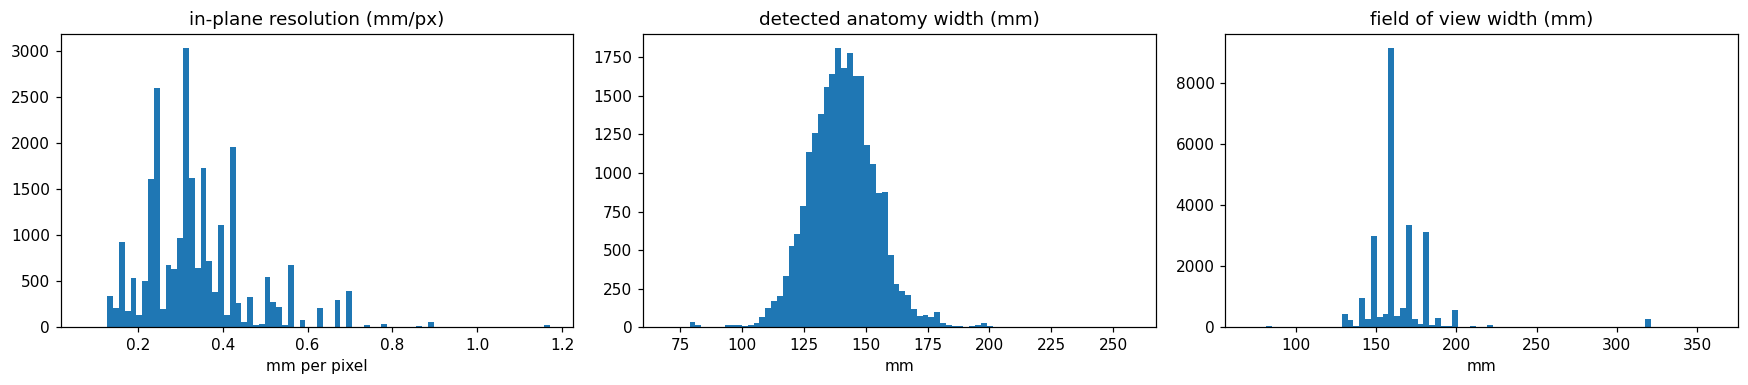

=== choosing mm/px and output size ===
anatomy width percentiles (mm):
0.500    140.6
0.900    157.2
0.950    162.0
0.990    177.7
0.999    203.9
1.000    257.8

coverage table — % of series whose anatomy fits fully in the frame:


out_px,256,320,384,448,512
mm_per_px,,,,,
0.30,0.02,0.30,0.47,6.65,38.36
0.35,0.23,0.42,6.65,42.40,95.95
0.40,0.37,2.42,38.36,95.95,99.53
0.45,0.47,18.96,87.46,99.45,99.83
0.50,2.42,70.32,98.04,99.80,99.94


(each cell = % of series fully contained; aim for >99.5%)

physical extent covered (mm) for the same grid:


out_px,256,320,384,448,512
mm_per_px,,,,,
0.30,76.8,96.0,115.2,134.4,153.6
0.35,89.6,112.0,134.4,156.8,179.2
0.40,102.4,128.0,153.6,179.2,204.8
0.45,115.2,144.0,172.8,201.6,230.4
0.50,128.0,160.0,192.0,224.0,256.0


=== resampling direction at a few targets ===
  target 0.35 mm/px: 60.7% of series downsampled, 39.3% upsampled (upsampling invents no new detail)
  target 0.4 mm/px: 75.4% of series downsampled, 24.6% upsampled (upsampling invents no new detail)
  target 0.45 mm/px: 86.5% of series downsampled, 13.5% upsampled (upsampling invents no new detail)


In [2]:
# --- 07: load the full pixel scan and join it to the series metadata ---------
# SELF-CONTAINED: this cell runs on a fresh kernel. Everything it needs is
# imported/loaded below, guarded so a rerun in a warm kernel stays fast.
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 110

RAW, STATS = Path("../data/raw"), Path("../data/stats")
LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
          "Medial OA", "Lateral OA", "PF OA", "Effusion",
          "Synovitis", "Baker's", "Contusion", "Fracture"]

if "train" not in globals():
    train = pd.read_csv(RAW / "train.csv")
if "train_ser" not in globals():
    train_ser = pd.read_csv(RAW / "train_series.csv")
if "lang" not in train.columns:                      # ~40s, only on a cold kernel
    try:
        from langdetect import detect, DetectorFactory
        DetectorFactory.seed = 0
        def _lang(t):
            try:
                return detect(str(t)[:2000])
            except Exception:
                return "??"
        train["lang"] = [_lang(t) for t in train["Report"].fillna("")]
    except ImportError:
        train["lang"] = "??"
        print("[!] pip install langdetect  (language column unavailable)")

# data/stats/ was produced by modal_scripts/modal_scan_dicoms.py, which decoded
# every one of the 819,078 training slices straight from the zip on Modal.
# series_stats.csv has one row per series; that is what preprocessing consumes.
sstat = pd.read_csv(STATS / "series_stats.csv")
print(f"series_stats.csv: {sstat.shape}")
print("columns:", list(sstat.columns))

# join the plane / fluid flags and the study-level language onto every series
meta = train_ser.rename(columns={"StudyInstanceUID": "study", "SeriesInstanceUID": "series"})
S = sstat.merge(meta, on=["study", "series"], how="left", validate="one_to_one")
S["lang"] = S["study"].map(train.set_index("StudyInstanceUID")["lang"])
S["slot"] = np.select(
    [(S.Anatomical_Plane == "Sagittal") & (S.Fluid_Sensitive == 0),
     (S.Anatomical_Plane == "Sagittal") & (S.Fluid_Sensitive == 1),
     (S.Anatomical_Plane == "Coronal")  & (S.Fluid_Sensitive == 1),
     (S.Anatomical_Plane == "Axial")    & (S.Fluid_Sensitive == 1),
     (S.Anatomical_Plane == "Coronal")  & (S.Fluid_Sensitive == 0),
     (S.Anatomical_Plane == "Axial")    & (S.Fluid_Sensitive == 0)],
    ["sag_plain", "sag_fluid", "cor_fluid", "ax_fluid", "cor_plain", "ax_plain"],
    default="?")

print(f"\nmerged: {len(S)} series; unmatched plane/fluid: {S.Anatomical_Plane.isna().sum()}")
print(f"slots assigned: {(S.slot != '?').sum()} / {len(S)}")

# derived physical quantities — this is what actually matters for preprocessing
S["fov_h_mm"]   = S["rows"] * S["pixel_spacing_r"]      # frame height in millimetres
S["fov_w_mm"]   = S["cols"] * S["pixel_spacing_c"]
S["anat_h_mm"]  = S["crop_h"] * S["pixel_spacing_r"]    # detected knee height
S["anat_w_mm"]  = S["crop_w"] * S["pixel_spacing_c"]
S["depth_mm"]   = S["n_slices"] * S["spacing_between"].fillna(S["slice_thickness"])
S["megapixels"] = S["rows"] * S["cols"] * S["n_slices"] / 1e6

# --- how trustworthy is each row? the scan recorded a per-slice sanity check ---
print("\n=== foreground-detection reliability ===")
print(f"series with >=90% of slices passing : {(S.fg_ok_frac >= 0.9).mean():.2%}")
print(f"series with >=50% passing           : {(S.fg_ok_frac >= 0.5).mean():.2%}")
print("Rows below 50% are excluded from the physical-size stats below, since a")
print("failed detection makes anat_w_mm meaningless.")
G = S[S.fg_ok_frac >= 0.5].copy()          # 'good' rows for anatomy-size questions
print(f"-> using {len(G)} of {len(S)} series for size analysis")

# --- per slot: what does each of the 4 model inputs actually look like? -------
print("\n=== per-slot profile (medians unless stated) ===")
prof = S.groupby("slot").agg(
    series=("series", "size"),
    studies=("study", "nunique"),
    n_slices=("n_slices", "median"),
    slices_p95=("n_slices", lambda s: s.quantile(.95)),
    rows=("rows", "median"),
    cols=("cols", "median"),
    mm_per_px=("pixel_spacing_c", "median"),
    thickness=("slice_thickness", "median"),
    fov_w_mm=("fov_w_mm", "median"),
    depth_mm=("depth_mm", "median"),
).round(2)
display(prof.loc[[s for s in ["sag_plain", "sag_fluid", "cor_fluid", "ax_fluid",
                              "cor_plain", "ax_plain"] if s in prof.index]])

# --- how much does in-plane resolution vary? this is the scale problem --------
print("\n=== pixel spacing (mm per pixel) — the source of scale variation ===")
print(S["pixel_spacing_c"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(3).to_string())
print(f"ratio p99/p1 = {S.pixel_spacing_c.quantile(.99) / S.pixel_spacing_c.quantile(.01):.2f}x")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
axes[0].hist(S["pixel_spacing_c"].dropna(), bins=80)
axes[0].set_title("in-plane resolution (mm/px)"); axes[0].set_xlabel("mm per pixel")
axes[1].hist(G["anat_w_mm"].dropna(), bins=80)
axes[1].set_title("detected anatomy width (mm)"); axes[1].set_xlabel("mm")
axes[2].hist(S["fov_w_mm"].dropna(), bins=80)
axes[2].set_title("field of view width (mm)"); axes[2].set_xlabel("mm")
plt.tight_layout(); plt.show()

# --- choosing the resampling target ------------------------------------------
# If we resample every series to a fixed mm/px, then a fixed output size in
# pixels corresponds to a fixed physical extent. We need that extent to contain
# the knee for essentially every study.
print("=== choosing mm/px and output size ===")
print("anatomy width percentiles (mm):")
print(G["anat_w_mm"].quantile([.5, .9, .95, .99, .999, 1.0]).round(1).to_string())

print("\ncoverage table — % of series whose anatomy fits fully in the frame:")
rows_ = []
for mm_px in [0.30, 0.35, 0.40, 0.45, 0.50]:
    for out_px in [256, 320, 384, 448, 512]:
        extent = mm_px * out_px                     # millimetres covered by the frame
        fits = ((G["anat_w_mm"] <= extent) & (G["anat_h_mm"] <= extent)).mean()
        rows_.append({"mm_per_px": mm_px, "out_px": out_px,
                      "covers_mm": round(extent, 1), "fits_%": round(fits * 100, 2)})
cov = pd.DataFrame(rows_)
display(cov.pivot(index="mm_per_px", columns="out_px", values="fits_%"))
print("(each cell = % of series fully contained; aim for >99.5%)")
print("\nphysical extent covered (mm) for the same grid:")
display(cov.pivot(index="mm_per_px", columns="out_px", values="covers_mm"))

# --- would resampling UPscale most series (bad: invents detail)? --------------
print("=== resampling direction at a few targets ===")
for mm_px in [0.35, 0.40, 0.45]:
    down = (S["pixel_spacing_c"] < mm_px).mean()   # native finer than target -> downsample
    print(f"  target {mm_px} mm/px: {down:.1%} of series downsampled, "
          f"{1 - down:.1%} upsampled (upsampling invents no new detail)")


=== how many series compete for each (study, slot) ===
1    18436
2     2777
3      109
4        7
5        4
6        1

(study, slot) pairs with a contest: 2898
studies affected: 1936

by slot:
sag_plain    865
cor_plain    570
sag_fluid    511
cor_fluid    357
ax_fluid     298
ax_plain     297

=== inside a contest, how different are the candidates? ===
       slices_ratio  res_ratio  area_ratio  depth_ratio
count       2898.00    2898.00     2898.00      2898.00
mean           1.40       1.16        1.42         1.35
std            1.01       0.31        0.91         0.69
min            1.00       1.00        1.00         1.00
50%            1.00       1.08        1.17         1.00
90%            2.00       1.27        1.78         2.36
99%            6.91       2.67        6.25         3.92
max            8.09       5.75       16.00         4.95

contests where all candidates share the same SeriesDescription: 23.7%
-> if they are identical repeats, the choice barely matters;
   if

,most_slices,finest_res,largest_area,most_coverage,lowest_series_number
most_slices,100.0,60.9,64.8,94.3,62.1
finest_res,60.9,100.0,93.4,62.5,52.3
largest_area,64.8,93.4,100.0,67.8,54.8
most_coverage,94.3,62.5,67.8,100.0,63.4
lowest_series_number,62.1,52.3,54.8,63.4,100.0



=== consequences of each rule (medians over the contested slots) ===


,median_slices,median_mm_px,median_depth_mm,median_fov_mm,pct_over_100_slices
most_slices,30.0,0.31,105.00,160.0,6.69
finest_res,29.0,0.28,99.00,160.0,3.97
largest_area,29.0,0.29,101.35,160.0,4.28
most_coverage,30.0,0.31,105.60,160.0,4.80
lowest_series_number,30.0,0.29,105.60,160.0,4.14




=== slices per series, overall and by slot ===
count    24371.0
mean        33.6
std         26.6
min         11.0
50%         30.0
90%         39.0
95%         45.0
99%        160.0
99.9%      320.0
max        320.0

by slot:
            count  mean   std   min   50%    95%    99%    max
slot                                                          
ax_fluid   4719.0  39.5  32.0  12.0  32.0  144.0  186.0  192.0
ax_plain   1179.0  41.0  32.0  14.0  32.0   80.7  200.0  254.0
cor_fluid  4624.0  28.5   6.3  15.0  30.0   38.0   42.0   80.0
cor_plain  3985.0  28.0   6.1  11.0  30.0   37.0   40.0   48.0
sag_fluid  4667.0  35.5  41.5  15.0  29.0   47.0  320.0  320.0
sag_plain  5197.0  33.7  21.2  11.0  30.0   60.4  136.0  200.0

=== the 709 series with >100 slices ===
studies affected: 565 (12.8%)

slot:
slot
ax_fluid     317
sag_plain    188
sag_fluid    148
ax_plain      56

top series descriptions:
series_desc
t2_de3d_we_tra_Patella_fit_T    265
DummySeriesDesc!                196
SAG 3D

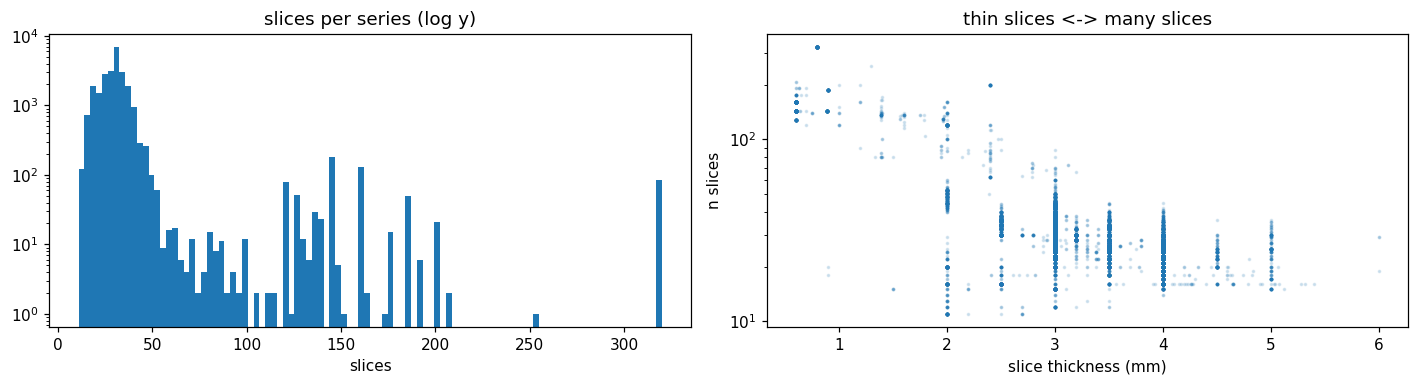

=== storage for the 4 slots at 512x512 uint8, by slice cap ===
  cap=None:   592,889 slices    144.7 GiB raw  ~  57.9 GiB compressed  (series truncated: 0.0%)
  cap=  32:   485,692 slices    118.6 GiB raw  ~  47.4 GiB compressed  (series truncated: 33.2%)
  cap=  40:   511,344 slices    124.8 GiB raw  ~  49.9 GiB compressed  (series truncated: 7.2%)
  cap=  48:   519,421 slices    126.8 GiB raw  ~  50.7 GiB compressed  (series truncated: 4.4%)
  cap=  64:   529,646 slices    129.3 GiB raw  ~  51.7 GiB compressed  (series truncated: 3.5%)
  cap=  96:   548,149 slices    133.8 GiB raw  ~  53.5 GiB compressed  (series truncated: 3.3%)

NOTE: a cap loses anatomy only if the extra slices cover extra knee.
      For 3D sequences they do not — they cover the SAME knee more finely,
      so resampling to a fixed mm BETWEEN slices is better than a hard cap.

=== through-plane spacing (mm between slice centres) ===
count    22792.00
mean         3.70
std          0.84
min          0.40
5%       

In [3]:
# --- 08: duplicate-series tie-break + slice-count policy ---------------------
# SELF-CONTAINED. Two decisions preprocessing needs:
#   (a) 1936 studies have >1 series competing for the same slot. Which one wins?
#   (b) some series have 320 slices. Cap them, subsample them, or keep them?
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 110
RAW, STATS = Path("../data/raw"), Path("../data/stats")

if "S" not in globals() or "slot" not in globals().get("S", pd.DataFrame()).columns:
    _tr_ser = pd.read_csv(RAW / "train_series.csv").rename(
        columns={"StudyInstanceUID": "study", "SeriesInstanceUID": "series"})
    S = pd.read_csv(STATS / "series_stats.csv").merge(_tr_ser, on=["study", "series"], how="left")
    S["slot"] = np.select(
        [(S.Anatomical_Plane == "Sagittal") & (S.Fluid_Sensitive == 0),
         (S.Anatomical_Plane == "Sagittal") & (S.Fluid_Sensitive == 1),
         (S.Anatomical_Plane == "Coronal")  & (S.Fluid_Sensitive == 1),
         (S.Anatomical_Plane == "Axial")    & (S.Fluid_Sensitive == 1),
         (S.Anatomical_Plane == "Coronal")  & (S.Fluid_Sensitive == 0),
         (S.Anatomical_Plane == "Axial")    & (S.Fluid_Sensitive == 0)],
        ["sag_plain", "sag_fluid", "cor_fluid", "ax_fluid", "cor_plain", "ax_plain"],
        default="?")
    S["pixel_spacing_c"] = S["pixel_spacing_c"].astype(float)
S["depth_mm"] = S["n_slices"] * S["spacing_between"].fillna(S["slice_thickness"])
S["fov_w_mm"] = S["cols"] * S["pixel_spacing_c"]

SLOT4 = ["sag_plain", "sag_fluid", "cor_fluid", "ax_fluid"]

# =============================================================================
# (a) DUPLICATES — when a study has several series for one slot
# =============================================================================
grp = S.groupby(["study", "slot"])
dup_sizes = grp.size()
print("=== how many series compete for each (study, slot) ===")
print(dup_sizes.value_counts().sort_index().to_string())
dup_keys = dup_sizes[dup_sizes > 1].index
print(f"\n(study, slot) pairs with a contest: {len(dup_keys)}")
print(f"studies affected: {len({k[0] for k in dup_keys})}")
print("\nby slot:")
print(pd.Series([k[1] for k in dup_keys]).value_counts().to_string())

D = S.set_index(["study", "slot"]).loc[dup_keys].reset_index()
print(f"\n=== inside a contest, how different are the candidates? ===")
def _spread(g, col):
    lo, hi = g[col].min(), g[col].max()
    return hi / lo if lo and lo > 0 else np.nan

cmp = D.groupby(["study", "slot"]).apply(lambda g: pd.Series({
    "n_cand":        len(g),
    "slices_ratio":  _spread(g, "n_slices"),
    "res_ratio":     _spread(g, "pixel_spacing_c"),
    "area_ratio":    _spread(g.assign(a=g["rows"] * g["cols"]), "a"),
    "depth_ratio":   _spread(g, "depth_mm"),
    "same_desc":     g["series_desc"].nunique() == 1,
}))
print(cmp[["slices_ratio", "res_ratio", "area_ratio", "depth_ratio"]]
      .describe(percentiles=[.5, .9, .99]).round(2).to_string())
print(f"\ncontests where all candidates share the same SeriesDescription: "
      f"{cmp['same_desc'].mean():.1%}")
print("-> if they are identical repeats, the choice barely matters;")
print("   if they differ a lot, the rule matters and must be justified.")

print("\n=== what would each candidate tie-break rule pick? ===")
def _pick(g, by, asc=False):
    return g.sort_values(by, ascending=asc).iloc[0]["series"]

rules = {
    "most_slices":   lambda g: _pick(g, "n_slices"),
    "finest_res":    lambda g: _pick(g, "pixel_spacing_c", asc=True),
    "largest_area":  lambda g: _pick(g.assign(a=g["rows"] * g["cols"]), "a"),
    "most_coverage": lambda g: _pick(g, "depth_mm"),
    "lowest_series_number": lambda g: _pick(g, "series_number", asc=True),
}
picks = pd.DataFrame({name: D.groupby(["study", "slot"]).apply(fn)
                      for name, fn in rules.items()})
print("how often do two rules agree?")
agree = pd.DataFrame({a: {b: (picks[a] == picks[b]).mean() for b in picks} for a in picks})
display((agree * 100).round(1))

print("\n=== consequences of each rule (medians over the contested slots) ===")
info = S.set_index("series")
summary = {}
for name in rules:
    chosen = info.loc[picks[name]]
    summary[name] = {
        "median_slices":   chosen["n_slices"].median(),
        "median_mm_px":    chosen["pixel_spacing_c"].median(),
        "median_depth_mm": chosen["depth_mm"].median(),
        "median_fov_mm":   chosen["fov_w_mm"].median(),
        "pct_over_100_slices": (chosen["n_slices"] > 100).mean() * 100,
    }
display(pd.DataFrame(summary).T.round(2))

# =============================================================================
# (b) SLICE COUNT — the long tail
# =============================================================================
print("\n\n=== slices per series, overall and by slot ===")
print(S["n_slices"].describe(percentiles=[.5, .9, .95, .99, .999]).round(1).to_string())
print("\nby slot:")
print(S.groupby("slot")["n_slices"].describe(percentiles=[.5, .95, .99]).round(1).to_string())

big = S[S["n_slices"] > 100]
print(f"\n=== the {len(big)} series with >100 slices ===")
print(f"studies affected: {big['study'].nunique()} ({big['study'].nunique()/S['study'].nunique():.1%})")
print("\nslot:"); print(big["slot"].value_counts().to_string())
print("\ntop series descriptions:"); print(big["series_desc"].value_counts().head(8).to_string())
print("\nslice thickness of these vs the rest:")
print(f"  >100 slices: median thickness {big['slice_thickness'].median():.2f} mm, "
      f"depth {big['depth_mm'].median():.0f} mm")
print(f"  <=100      : median thickness {S[S.n_slices<=100]['slice_thickness'].median():.2f} mm, "
      f"depth {S[S.n_slices<=100]['depth_mm'].median():.0f} mm")
print("-> thin slices covering the same knee = a 3D sequence, not extra anatomy.")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(S["n_slices"], bins=100); axes[0].set_yscale("log")
axes[0].set_title("slices per series (log y)"); axes[0].set_xlabel("slices")
axes[1].scatter(S["slice_thickness"], S["n_slices"], s=2, alpha=.15)
axes[1].set_xlabel("slice thickness (mm)"); axes[1].set_ylabel("n slices")
axes[1].set_title("thin slices <-> many slices"); axes[1].set_yscale("log")
plt.tight_layout(); plt.show()

# --- storage cost of the 4 slots at 512x512 uint8, under different caps -------
print("=== storage for the 4 slots at 512x512 uint8, by slice cap ===")
best = (S[S.slot.isin(SLOT4)]
        .sort_values("n_slices", ascending=False)
        .groupby(["study", "slot"]).first())          # 'most_slices' rule, as an example
for cap in [None, 32, 40, 48, 64, 96]:
    n = best["n_slices"] if cap is None else best["n_slices"].clip(upper=cap)
    gib = n.sum() * 512 * 512 / 1024**3
    print(f"  cap={str(cap):>4}: {n.sum():9,.0f} slices  "
          f"{gib:7.1f} GiB raw  ~{gib/2.5:6.1f} GiB compressed  "
          f"(series truncated: {(best['n_slices'] > (cap or 1e9)).mean():.1%})")
print("\nNOTE: a cap loses anatomy only if the extra slices cover extra knee.")
print("      For 3D sequences they do not — they cover the SAME knee more finely,")
print("      so resampling to a fixed mm BETWEEN slices is better than a hard cap.")

print("\n=== through-plane spacing (mm between slice centres) ===")
print(S["spacing_between"].describe(percentiles=[.05, .5, .95, .99]).round(2).to_string())
print("\nif we resample to a fixed mm between slices, how many slices result?")
for mm in [2.0, 3.0, 3.5, 4.0]:
    n = (S["depth_mm"] / mm)
    print(f"  {mm} mm spacing -> median {n.median():.0f} slices, "
          f"p95 {n.quantile(.95):.0f}, p99 {n.quantile(.99):.0f}")
